Preprocessing

In [20]:
# import cv2 as cv
# import matplotlib.pyplot as plt
# import os

# # Load data

# dataset = '/Applications/MAMP/htdocs/local/kodingakademi/Python/python4/facerecognition/materi/image'
# dir_cat = '/Applications/MAMP/htdocs/local/kodingakademi/Python/python4/facerecognition/materi/image/cat'
# dir_dog = '/Applications/MAMP/htdocs/local/kodingakademi/Python/python4/facerecognition/materi/image/dog'

# for label, category in enumerate(os.listdir(dataset)):
#     category_path = os.path.join(dataset, category)
#     if category_path == dir_cat or category_path == dir_dog:
#         for img_name in os.listdir(category_path):
#             img_path = os.path.join(category_path, img_name)
#             image = cv.imread(img_path)



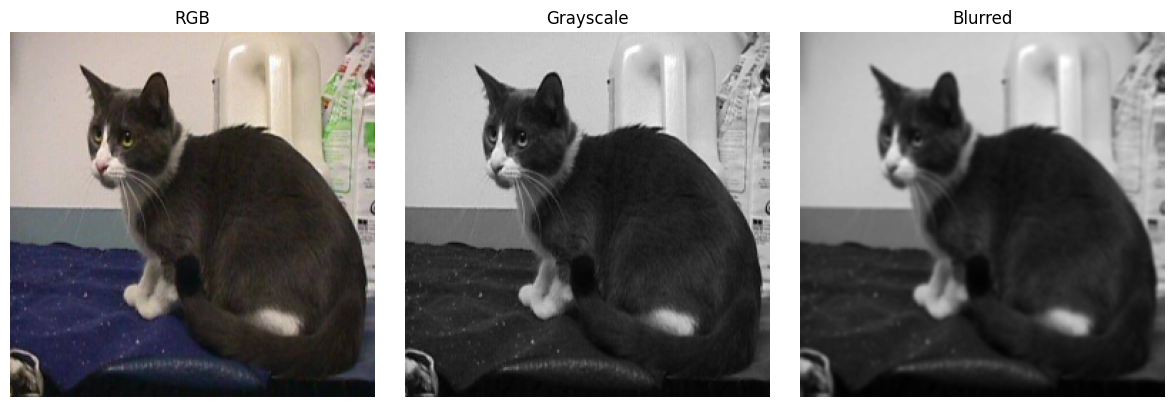

In [21]:
import cv2 as cv
import matplotlib.pyplot as plt

image = cv.imread('cat.jpg')
image = cv.resize(image, (256, 256))
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

blurred_image = cv.GaussianBlur(gray_image, (5, 5), 0)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_rgb)
plt.title('RGB')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gray_image, cmap='gray')
plt.title('Grayscale')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(blurred_image, cmap='gray')
plt.title('Blurred')
plt.axis('off')

plt.tight_layout()
plt.show()


Ekstraksi

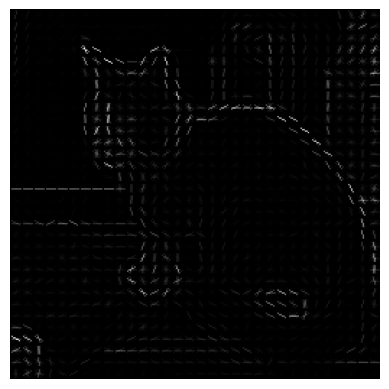

features = 34596


In [28]:
from skimage.feature import hog

features, hog_image = hog(blurred_image, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)

plt.imshow(hog_image, cmap='gray')
plt.axis('off')
plt.show()

print(f"features = {len(features)}")

Model klasifikasi random forest

In [35]:
import os
import cv2 as cv
from skimage.feature import hog
from sklearn.model_selection import train_test_split

dataset = '/Applications/MAMP/htdocs/local/kodingakademi/Python/python4/facerecognition/materi/image'
dir_cat = '/Applications/MAMP/htdocs/local/kodingakademi/Python/python4/facerecognition/materi/image/cat'
dir_dog = '/Applications/MAMP/htdocs/local/kodingakademi/Python/python4/facerecognition/materi/image/dog'

X, y = [], []

for label, category in enumerate(os.listdir(dataset)):
    category_path = os.path.join(dataset, category)
    if category_path == dir_cat or category_path == dir_dog:
        for img_name in os.listdir(category_path):
            img_path = os.path.join(category_path, img_name)
            image = cv.imread(img_path)
            image = cv.resize(image, (256, 256))
            gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
            
            features, _ = hog(gray_image, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
            print(label)
            print(img_name)
            print(features)
            X.append(features)
            y.append(label)

# Bagi dataset menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

0
cat.6.jpg
[0.35468069 0.00933048 0.         ... 0.26823237 0.0258289  0.23366037]
0
cat.30.jpg
[0.35344239 0.21590877 0.         ... 0.         0.02710206 0.0383281 ]
0
cat.24.jpg
[0.25726195 0.25726195 0.05943701 ... 0.09282628 0.11007842 0.        ]
0
cat.18.jpg
[0.23909326 0.0410425  0.11823889 ... 0.24022914 0.12123963 0.09832557]
0
cat.19.jpg
[0.25720736 0.25720736 0.19947651 ... 0.06174155 0.25961997 0.15910646]
0
cat.25.jpg
[0.03024586 0.02536192 0.06702452 ... 0.03527201 0.         0.        ]
0
cat.31.jpg
[0.17698503 0.28610274 0.28610274 ... 0.01383528 0.00804383 0.        ]
0
cat.7.jpg
[0.34211328 0.11942395 0.07101542 ... 0.12005693 0.10149691 0.09711053]
0
cat.5.jpg
[0.04063192 0.         0.01768068 ... 0.28740724 0.28740724 0.10742679]
0
cat.27.jpg
[0.2535396  0.10684964 0.17205528 ... 0.19297876 0.10441759 0.13826977]
0
cat.33.jpg
[0.22709961 0.05976048 0.15754552 ... 0.09280641 0.11739186 0.        ]
0
cat.32.jpg
[0.2093867  0.19612714 0.10644506 ... 0.04443966 0.0583

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Akurasi:", accuracy_score(y_test, y_pred))

Akurasi: 0.7777777777777778


Prediksi gambar baru

In [34]:
image = cv.imread("cat.1.jpg")
image = cv.resize(image, (256, 256))
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Ekstraksi fitur HOG dari gambar baru
features, _ = hog(gray_image, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)

# Prediksi
prediction = model.predict([features])[0]
label_map = {0: 'Kucing', 2: 'Anjing'}
print(f"Prediksi: {label_map[prediction]}")

Prediksi: Anjing
